In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
print("DataSet loaded succesfully")
df = pd.read_csv('Diabetis_data.csv')

DataSet loaded succesfully


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Gender  10000 non-null  object 
 1   Height  10000 non-null  float64
 2   Weight  10000 non-null  float64
dtypes: float64(2), object(1)
memory usage: 234.5+ KB


In [ ]:
df.describe()

,Height,Weight
count,10000.000000,10000.000000
mean,66.367560,161.440357
std,3.847528,32.108439
min,54.263133,64.700127
25%,63.505620,135.818051
50%,66.318070,161.212928
75%,69.174262,187.169525
max,78.998742,269.989699


In [ ]:
df.shape

(10000, 3)

In [ ]:
print("\nMissing values:")
print(df.isnull().sum())
print("Number of duplicates:", df.duplicated().sum())


Missing values:
Gender    0
Height    0
Weight    0
dtype: int64
Number of duplicates: 0


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])

In [ ]:
Q1 = df['Height'].quantile(0.25)
Q3 = df['Height'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [ ]:
print(f"\nHeight Limits -> Lower: {lower_bound:.2f}, Upper: {upper_bound:.2f}")


Height Limits -> Lower: 55.00, Upper: 77.68


In [ ]:
df = df[(df['Height'] >= lower_bound) & (df['Height'] <= upper_bound)]
print("Dataset shape after removing outliers:", df.shape)

Dataset shape after removing outliers: (9992, 3)


In [ ]:
X = df[['Height', 'Weight']]
y = df['Gender']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
scaler = StandardScaler()
cols_to_scale = ['Height', 'Weight']
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("\n=== Model Metrics ===")
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)


=== Model Metrics ===
Training Accuracy: 0.9204303765795071
Testing Accuracy: 0.9144572286143071


Confusion Matrix:
 [[908  84]
 [ 87 920]]


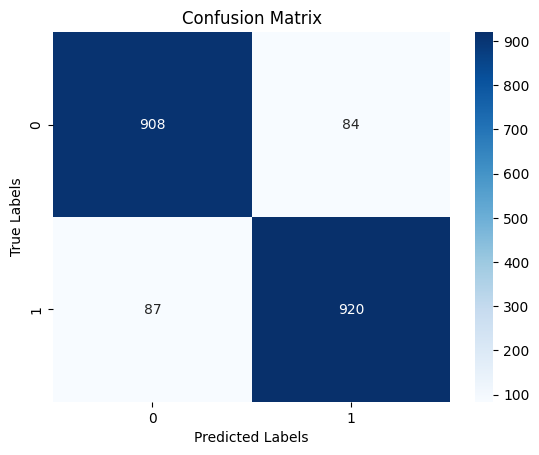

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

conf_mat = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:\n', conf_mat)

sns.heatmap(conf_mat, annot=True, fmt='d', cmap="Blues")
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

class_report = classification_report(y_test, y_pred)
print('\nClassification Report:\n', class_report)

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
print('AUC Score:', auc_score)


Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.92      0.91       992
           1       0.92      0.91      0.91      1007

    accuracy                           0.91      1999
   macro avg       0.91      0.91      0.91      1999
weighted avg       0.91      0.91      0.91      1999

AUC Score: 0.9706309863215556


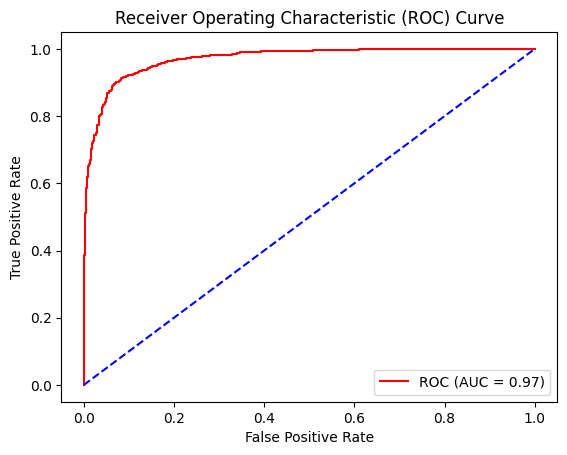

In [ ]:
plt.plot(fpr, tpr, color='red', label=f'ROC (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='blue', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()